# StreamLoop — Hyperparameter Tuning

**Proyecto 4Geeks:** clasificación de cancelación
de suscripciones con IBM Telco Customer Churn.

Este notebook presenta la metodología y los resultados
ya guardados. No repite las búsquedas ni las
evaluaciones del conjunto de prueba.

In [1]:
import json
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

from scripts.churn_baseline import (
    load_dataset, split_dataset, build_pipeline
)

ROOT = Path.cwd()
R = ROOT / "reports"

X, y, missing = load_dataset()
X_train, X_test, y_train, y_test = split_dataset(X, y)

print("Dataset:", len(X), "clientes")
print("Entrenamiento:", len(X_train))
print("Prueba reservada:", len(X_test))
print("TotalCharges faltantes:", missing)
print("Distribucion train:")
print(y_train.value_counts().to_string())

Dataset: 7043 clientes
Entrenamiento: 5634
Prueba reservada: 1409
TotalCharges faltantes: 11
Distribucion train:
Churn
0    4139
1    1495


## 1. Pipeline y métrica

El preprocesamiento numérico y categórico permanece
dentro del pipeline para evitar fuga de información.

Utilizamos **F2-score**, que da mayor prioridad
a la detección de churn (recall), considerando
también los falsos positivos.

In [2]:
pipeline = build_pipeline(X_train)
print("Pasos:", list(pipeline.named_steps))
print("Clasificador:", pipeline.named_steps["classifier"])
print("Predictores:", X_train.shape[1])

Pasos: ['preprocess', 'classifier']
Clasificador: RandomForestClassifier(n_jobs=2, random_state=42)
Predictores: 19


## 2. RandomizedSearchCV y GridSearchCV

Ambos métodos usaron cinco folds estratificados
sobre entrenamiento. Los resultados fueron guardados
por los scripts de búsqueda y se leen a continuación.

In [3]:
random_cv = json.loads(
    (R / "random_search_summary.json").read_text()
)
grid_cv = json.loads(
    (R / "grid_search_summary.json").read_text()
)

comparison = pd.DataFrame([
    {
        "Modelo": "Baseline",
        "F2 CV": random_cv["baseline_cv_f2_mean"],
        "Desv. CV": random_cv["baseline_cv_f2_std"],
    },
    {
        "Modelo": "RandomizedSearchCV",
        "F2 CV": random_cv["random_cv_f2_mean"],
        "Desv. CV": random_cv["random_cv_f2_std"],
    },
    {
        "Modelo": "GridSearchCV",
        "F2 CV": grid_cv["grid_best_cv_f2_mean"],
        "Desv. CV": grid_cv["grid_best_cv_f2_std"],
    },
])
print(comparison.to_string(index=False))
print("\nMejores hiperparametros Grid:")
print(json.dumps(
    grid_cv["grid_best_parameters"], indent=2
))

            Modelo    F2 CV  Desv. CV
          Baseline 0.502486  0.029462
RandomizedSearchCV 0.722519  0.014097
      GridSearchCV 0.722519  0.014097

Mejores hiperparametros Grid:
{
  "classifier__class_weight": "balanced",
  "classifier__max_depth": 6,
  "classifier__max_features": "sqrt",
  "classifier__min_samples_leaf": 8,
  "classifier__min_samples_split": 8,
  "classifier__n_estimators": 80
}


In [4]:
grid_results = pd.read_csv(
    R / "grid_search_results.csv"
)
print("Mejores cinco combinaciones:")
print(
    grid_results[
        ["rank_test_score", "mean_test_score",
         "std_test_score"]
    ].head(5).to_string(index=False)
)

Mejores cinco combinaciones:
 rank_test_score  mean_test_score  std_test_score
               1         0.722519        0.014097
               1         0.722519        0.014097
               3         0.722484        0.016554
               3         0.722484        0.016554
               5         0.721093        0.017019


## 3. Evaluación del conjunto de prueba

Se comparan únicamente los resultados **ya
almacenados** de las dos evaluaciones permitidas:
baseline y modelo optimizado.

No ejecutamos nuevas predicciones sobre el test.

          Metrica  Baseline  Optimizado
         accuracy  0.777857    0.744500
        precision  0.603390    0.512069
           recall  0.475936    0.794118
         f2_score  0.496929    0.715318
average_precision  0.605715    0.646941


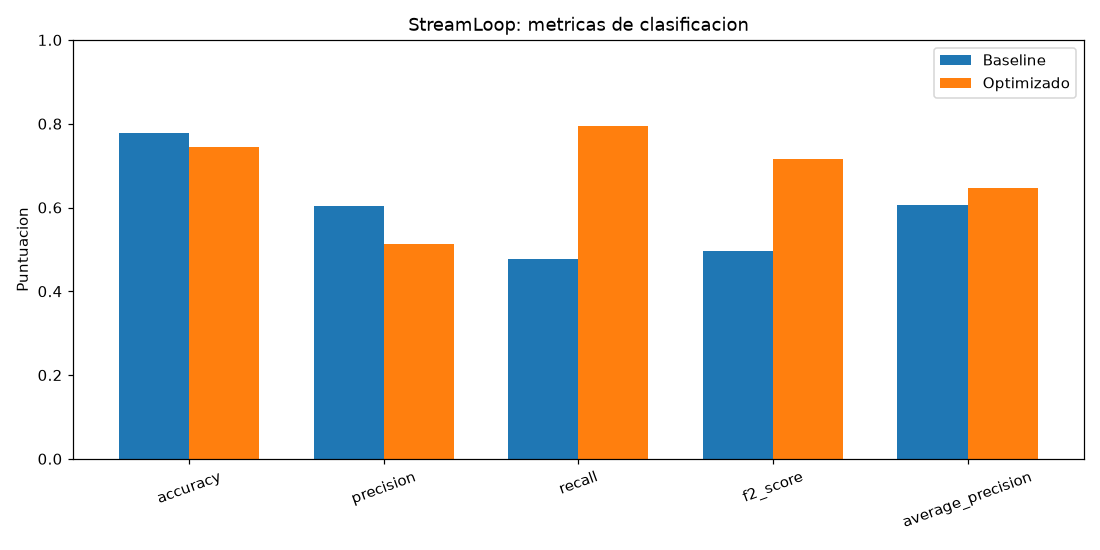

In [5]:
selection = json.loads(
    (R / "final_model_selection.json").read_text()
)
original = selection["baseline_test_metrics"]
optimized = selection["final_test_metrics"]

metrics = [
    "accuracy", "precision", "recall",
    "f2_score", "average_precision",
]

comparison_test = pd.DataFrame({
    "Metrica": metrics,
    "Baseline": [original[k] for k in metrics],
    "Optimizado": [optimized[k] for k in metrics],
})

print(comparison_test.to_string(index=False))

positions = np.arange(len(metrics))
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(
    positions - 0.18, comparison_test["Baseline"],
    width=0.36, label="Baseline"
)
ax.bar(
    positions + 0.18, comparison_test["Optimizado"],
    width=0.36, label="Optimizado"
)
ax.set_xticks(positions, metrics, rotation=20)
ax.set_ylabel("Puntuacion")
ax.set_ylim(0, 1)
ax.set_title("StreamLoop: metricas de clasificacion")
ax.legend()
fig.tight_layout()

## 4. Matriz de confusión

La matriz se construye a partir de los conteos
guardados; **no se reevalúa ningún modelo**.

Falsos negativos: 196 -> 77
Falsos positivos: 117 -> 283


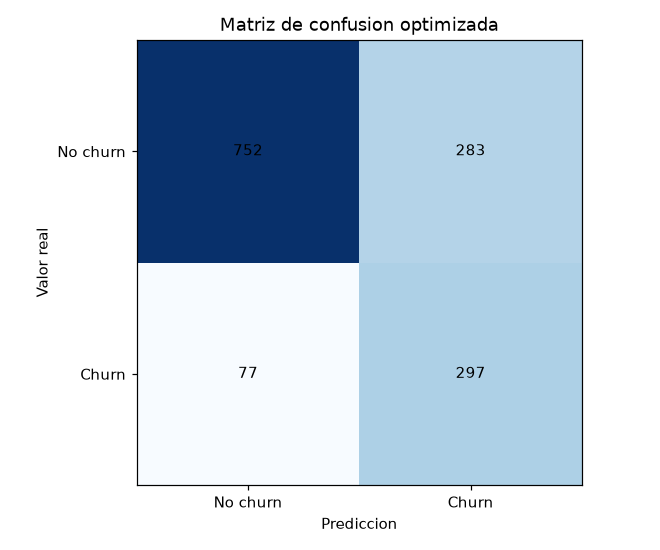

In [6]:
cm = np.array([
    [
        optimized["true_negative"],
        optimized["false_positive"],
    ],
    [
        optimized["false_negative"],
        optimized["true_positive"],
    ],
])

fig, ax = plt.subplots(figsize=(6, 5))
ax.imshow(cm, cmap="Blues")

for i in range(2):
    for j in range(2):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center", va="center",
            color="black"
        )

ax.set_xticks([0, 1], ["No churn", "Churn"])
ax.set_yticks([0, 1], ["No churn", "Churn"])
ax.set_xlabel("Prediccion")
ax.set_ylabel("Valor real")
ax.set_title("Matriz de confusion optimizada")
fig.tight_layout()

print(
    "Falsos negativos:",
    original["false_negative"], "->",
    optimized["false_negative"]
)
print(
    "Falsos positivos:",
    original["false_positive"], "->",
    optimized["false_positive"]
)

## 5. Conclusiones

- GridSearchCV igualó la mejor puntuación
  de RandomizedSearchCV.
- El modelo optimizado mejora recall y F2.
- También aumenta los falsos positivos:
  hay un costo potencial de campañas innecesarias.
- La selección se realizó solo con CV de train.
- La viabilidad económica requiere información
  de costos y valor de retención.

**Informe detallado:** `tuning_report.md`.